# Time aggregation: the manager sentiment series

Takes the report-level polarities in `sent_growth_fin_risk_10k_10q.parquet`,
collapses them to one observation per calendar month, smooths them, and writes
parquet to `manager_sentiment_results/`. To run the same steps on the 100 example
filings, switch `REPORTS_PATH` and `OUTPUT_PATH` to the commented sample paths.

Both steps are configurable:

| step | options |
|---|---|
| weighting | equal, or by any report-level column (market capitalization) |
| pooling | raw monthly mean by default; optional z-score or centering within `FORM_TYPE` |
| smoothing | default: backward 4-month average, then a full-sample StandardScaler. Optional: unnormalized 4-month average, two-sided or one-sided HP |

In [1]:
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

REPO_URL = "https://github.com/fabianslo108/manager_sentiment.git"
try:
    import google.colab
except ModuleNotFoundError:
    IS_COLAB = False
else:
    IS_COLAB = True

def is_repository(path):
    return (path / "code" / "scripts" / "utils.py").is_file() and (path / "input_data").is_dir()

search_paths = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
REPO_ROOT = next((path for path in search_paths if is_repository(path)), None)

if REPO_ROOT is None and IS_COLAB:
    REPO_ROOT = Path("/content/manager_sentiment")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_ROOT)], check=True)
    elif not is_repository(REPO_ROOT):
        raise FileExistsError(f"{REPO_ROOT} exists but is not a valid manager_sentiment checkout")

if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the repository. Run this notebook from within the manager_sentiment checkout."
    )

sys.path.insert(0, str(REPO_ROOT / "code" / "scripts"))


import time_aggregation as ta
from utils import (
    INPUT_DATA_DIR,
    MANAGER_SENTIMENT_DIR,
    SENTIMENT_RESULTS_DIR,
    set_seed,
)

set_seed(42)

print("runtime:", "Colab" if IS_COLAB else "local")
print("repo:", REPO_ROOT)
print("input:", INPUT_DATA_DIR)
print("sentiment scores:", SENTIMENT_RESULTS_DIR)
print("HP lambda for monthly data:", ta.HP_LAMBDA_MONTHLY)

runtime: Colab
repo: /content/manager_sentiment
input: /content/manager_sentiment/input_data
sentiment scores: /content/manager_sentiment/sentiment_extraction_results
HP lambda for monthly data: 129600


## Report-level input

In [2]:
# Resulting table for the whole sample
REPORTS_PATH = SENTIMENT_RESULTS_DIR / "sent_growth_fin_risk_10k_10q.parquet" 
OUTPUT_PATH = MANAGER_SENTIMENT_DIR / "manager_sentiment_monthly.parquet"

# Resulting table for the sample of 100 reports
# REPORTS_PATH = SENTIMENT_RESULTS_DIR / "sample_filings.parquet"
# OUTPUT_PATH = MANAGER_SENTIMENT_DIR / "manager_sentiment_monthly_sample.parquet"

reports = ta.load_reports(REPORTS_PATH)

POLARITIES = [
    # 'positive_financial_risk', 'negative_financial_risk', 'polarity_financial_risk',
    # 'positive_growth_MB', 'negative_growth_MB', 'polarity_growth_MB',
    # 'positive_growth_llama', 'negative_growth_llama', 'polarity_growth_llama'
]
POLARITIES = ['polarity_financial_risk', 'polarity_growth_llama']

wide = ta.prepare_reports(reports, polarities=POLARITIES)
print("filings:", len(wide))
print("source :", REPORTS_PATH.name)

05:47:51 | INFO    | time_aggregation | loaded 124053 row(s) from sent_growth_fin_risk_10k_10q.parquet
05:47:52 | WARNING | time_aggregation | averaged 4 extra duplicate row(s); 124049 filing(s) remain
05:47:52 | INFO    | time_aggregation | prepared 124049 filing(s), measures: polarity_financial_risk, polarity_growth_llama


filings: 124049
source : sent_growth_fin_risk_10k_10q.parquet


In [3]:
MEASURES = ta.score_columns(wide)
print("measures:", MEASURES)
print("filings :", len(wide))
wide[MEASURES].describe().round(4)

measures: ['polarity_financial_risk', 'polarity_growth_llama']
filings : 124049


,polarity_financial_risk,polarity_growth_llama
count,110392.0000,123988.0000
mean,0.0911,0.2284
std,0.1092,0.1740
min,-0.8652,-0.7697
25%,0.0381,0.1388
50%,0.1044,0.2326
75%,0.1568,0.3254
max,0.8984,0.8892


## Why equalize across form types

10-K and 10-Q filings do not arrive evenly across the calendar. If the two form
types sit at different levels or spreads, a plain pooled monthly mean picks up
the calendar composition as a mechanical annual cycle, and a regression later
reads that cycle as signal.

Two ways to remove it, and the choice is substantive:

- `standardize_method="zscore"` equalizes level **and** spread. It stops months
  dominated by the more dispersed form type from being mechanically more
  volatile, but it rescales the measure: a form type whose scores are tightly
  clustered gets stretched more than a dispersed one.
- `standardize_method="center"` removes only the level difference and leaves each
  form type's spread untouched.

The cells below show the composition, the two distributions and what each choice
does, so the decision rests on this sample rather than on a default.

In [4]:
wide["month"] = wide["FILING_DATE"].str[4:6]

composition = pd.crosstab(wide["month"], wide["FORM_TYPE"])
print("filings by calendar month and form type")
print(composition.to_string())
print()
print("score distribution by form type")
print(wide.groupby("FORM_TYPE")[MEASURES].agg(["mean", "std", "count"]).round(4).to_string())

filings by calendar month and form type
FORM_TYPE   10-K   10-Q
month                  
01           785   1244
02         19496   3004
03         28509   1020
04          2762   3568
05          1464  15059
06          1661   1157
07           773   3368
08          1596  12728
09          1905   1271
10           777   3889
11          1842  12994
12          1865   1312

score distribution by form type
          polarity_financial_risk                polarity_growth_llama               
                             mean     std  count                  mean     std  count
FORM_TYPE                                                                            
10-K                       0.0667  0.1385  49778                0.2356  0.2252  63425
10-Q                       0.1111  0.0713  60614                0.2208  0.0935  60563


In [5]:
# Default pooling is the plain equal-weight monthly mean of the raw scores.
# Optional: STANDARDIZE_BY = "FORM_TYPE" z-scores within form type before
# pooling (the comparison above). STANDARDIZE_METHOD = "center" removes only
# the level. WEIGHT_COL is an optional report-level weight such as market cap.
STANDARDIZE_BY = None
STANDARDIZE_METHOD = "zscore"     # used only when STANDARDIZE_BY is set
WEIGHT_COL = None

pooled = ta.aggregate_to_monthly(wide, MEASURES, standardize_by=None)
within = ta.aggregate_to_monthly(wide, MEASURES, standardize_by="FORM_TYPE",
                                 standardize_method=STANDARDIZE_METHOD)

measure = MEASURES[0]
by_calendar_month = pd.DataFrame(
    {
        "pooled": pooled.set_index(ta.MONTH_COL)[measure].groupby(lambda d: d.month).mean(),
        "equalized": within.set_index(ta.MONTH_COL)[measure].groupby(lambda d: d.month).mean(),
    }
)
print(f"average {measure} by calendar month")
print(by_calendar_month.round(4).to_string())
print()
print("month-to-month volatility of the monthly index (std of first differences):")
for label, frame in [("pooled", pooled), ("equalized", within)]:
    print(f"  {label:10s} {frame[measure].diff().std():.4f}")

05:51:50 | INFO    | time_aggregation | aggregated 124049 filing(s) into 252 month(s) (equal weighting)
05:51:50 | INFO    | time_aggregation | standardized ['polarity_financial_risk', 'polarity_growth_llama'] within ['FORM_TYPE'] (group sizes: {'10-K': 63435, '10-Q': 60614})
05:51:50 | INFO    | time_aggregation | aggregated 124049 filing(s) into 252 month(s) (equal weighting)


average polarity_financial_risk by calendar month
            pooled  equalized
year_month                   
1           0.1158     0.2237
2           0.0833     0.0326
3           0.0693    -0.0416
4           0.1043     0.0843
5           0.1052    -0.0553
6           0.1013     0.0780
7           0.1149     0.1254
8           0.1058    -0.0412
9           0.1102     0.1741
10          0.1179     0.1367
11          0.1021    -0.0788
12          0.1056     0.1461

month-to-month volatility of the monthly index (std of first differences):
  pooled     0.0226
  equalized  0.2075


## Market-cap weighting

ToDo:
 "finaldata_10k.sas7bdat"  contains only market cap for 10K until 2019.

In [6]:
# MKTCAP_PATH = REPO_ROOT / "input_data" / "finaldata_10k.sas7bdat"  
# mktcap = pd.read_sas(MKTCAP_PATH)

print("weighting:", WEIGHT_COL or "equal")

weighting: equal


## Build the series

The default is the Jiang construction: an equal-weight mean within each month,
a backward 4-month moving average of that mean, then a full-sample
`StandardScaler` of the average (`_ma4_norm`). The raw monthly mean is kept
with no suffix. The first three months of the average are missing.

The scaler's mean and standard deviation use the whole sample, including later
months. The same is true of the two-sided HP trend (`_hp`), which is optional:
the value at month *t* uses months after *t*. The optional `_hp1s` re-estimates
the filter on an expanding window and keeps only its last point.

In [7]:
# Default: 4-month backward average, then StandardScaler.
# Optional smoothers (uncomment to add the columns):
#   ("ma", {"window": 4}),                           # same average, not normalized
#   ("hp", {}),                                      # two-sided HP, look-ahead
#   ("hp", {"one_sided": True, "min_periods": 24}),  # expanding-window HP
SMOOTHING = [
    ("ma", {"window": 4, "normalize": True}),
]

series = ta.build_manager_sentiment(
    wide,
    value_cols=MEASURES,
    weight_col=WEIGHT_COL,
    standardize_by=STANDARDIZE_BY,
    standardize_method=STANDARDIZE_METHOD,
    smoothing=SMOOTHING,
)

print(series.shape)
series.tail()

00:05:09 | INFO    | time_aggregation | aggregated 124049 filing(s) into 252 month(s) (equal weighting)


(252, 6)


,year_month,n_obs,polarity_financial_risk,polarity_growth_llama,polarity_financial_risk_ma4_norm,polarity_growth_llama_ma4_norm
247,2023-08-01,654,0.109997,0.234064,0.420546,-0.193916
248,2023-09-01,127,0.138441,0.185056,0.772874,-0.579101
249,2023-10-01,253,0.122362,0.225066,0.943441,-0.242100
250,2023-11-01,674,0.117989,0.233511,0.915038,-0.103318
251,2023-12-01,102,0.150628,0.216741,1.390065,-0.249127


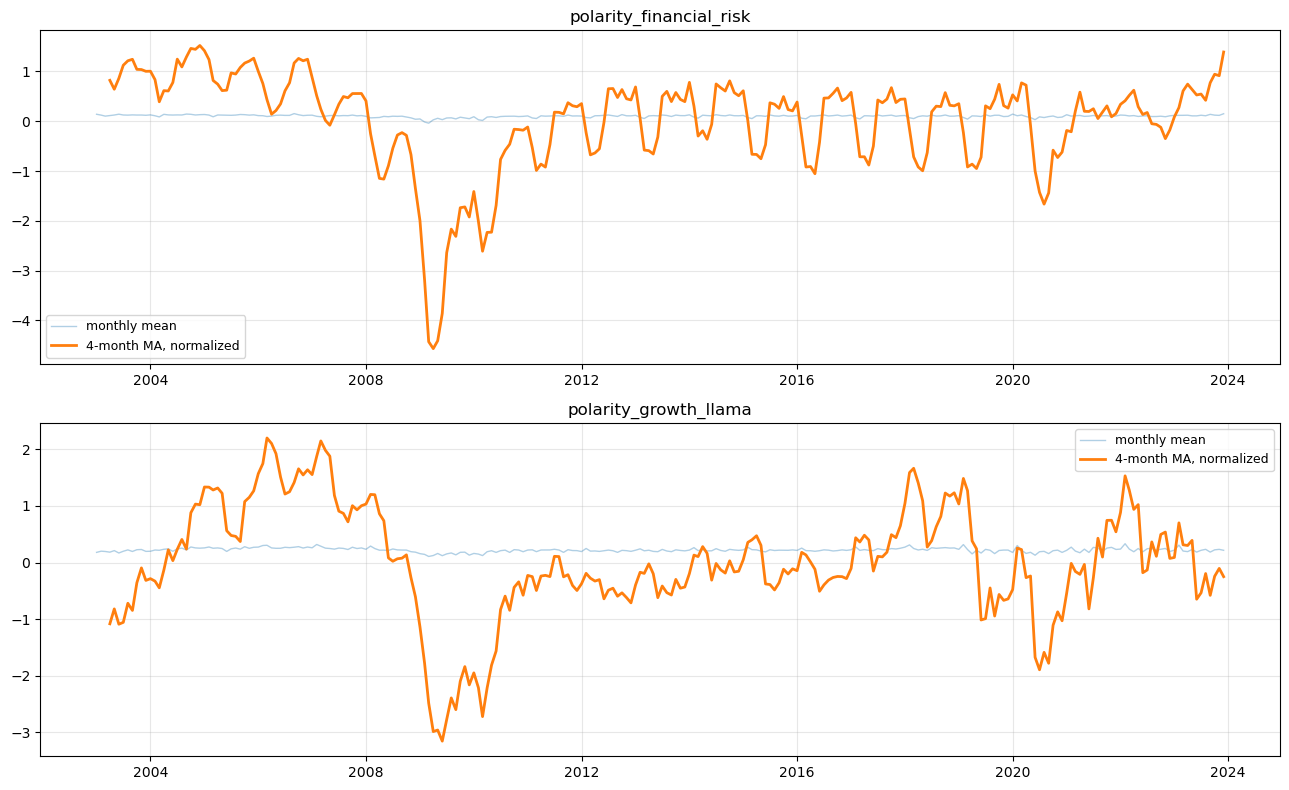

In [8]:
fig, axes = plt.subplots(len(MEASURES), 1, figsize=(13, 4 * len(MEASURES)), squeeze=False)

optional = [
    ("_ma4_norm", "4-month MA, normalized", "-"),
    ("_ma4", "4-month MA", "-"),
    ("_hp", "HP trend (two-sided)", "-"),
    ("_hp1s", "HP trend (one-sided)", "--"),
]
for ax, measure in zip(axes[:, 0], MEASURES):
    ax.plot(series[ta.MONTH_COL], series[measure], alpha=0.35, linewidth=1, label="monthly mean")
    for suffix, label, style in optional:
        column = f"{measure}{suffix}"
        if column in series.columns:
            ax.plot(series[ta.MONTH_COL], series[column], linewidth=2, linestyle=style, label=label)
    ax.set_title(measure)
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=9)

plt.tight_layout()
plt.show()

## Write the output

In [9]:
ta.save_time_series(series, OUTPUT_PATH)

print(series.shape, "->", OUTPUT_PATH)
print()
print("columns:")
for col in series.columns:
    print("  -", col)

00:05:10 | INFO    | time_aggregation | wrote 252 month(s) to /Users/natalya-vasileva/Desktop/manager_sentiment/manager_sentiment_results/manager_sentiment_monthly.parquet


(252, 6) -> /Users/natalya-vasileva/Desktop/manager_sentiment/manager_sentiment_results/manager_sentiment_monthly.parquet

columns:
  - year_month
  - n_obs
  - polarity_financial_risk
  - polarity_growth_llama
  - polarity_financial_risk_ma4_norm
  - polarity_growth_llama_ma4_norm
